# Admissions CRM analytics — synthetic case study
# Analítica CRM de admisiones — caso con datos sintéticos

> **EN — Synthetic data.** Every row, rate and amount in this notebook is **synthetic**, generated from the
> *synthetic scenario parameters* in `config/simulation_params.yaml` (seed 42). Differences between sources,
> routes or profiles reproduce those parameters; they are not findings about any real company, team or market.
> No causal effect is programmed for any intervention, so no causal claim is made.
>
> **ES — Datos sintéticos.** Todas las filas, tasas e importes de este notebook son **sintéticos**, generados a
> partir de los *parámetros del escenario sintético* de `config/simulation_params.yaml` (semilla 42). Las
> diferencias entre fuentes, rutas o perfiles reproducen esos parámetros; no son hallazgos sobre ninguna empresa,
> equipo o mercado reales. No se programa ningún efecto causal de ninguna intervención, así que no se afirma causalidad.

Definitions / Definiciones: `docs/kpi_definitions.md` · `docs/kpi_definitions.es.md`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import metrics   # single implementation of every table and KPI shown below (v1.1.0-f1)

pd.set_option("display.max_columns", 40, "display.width", 160)
ctx = metrics.load_context(ROOT / "data", ROOT / "config" / "simulation_params.yaml")
pop = metrics.population_counts(ctx)

# Chart style: one categorical order (validated reference palette), recessive grid, thin marks
BLUE, ORANGE, AQUA, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "font.size": 9.5, "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False})

# Presentation helpers only (formatting, no computation)
pct = lambda x: "—" if pd.isna(x) else f"{x:.1%}"
def fmt_rows(series, counts=(), hours=()):
    # Show a module Series as a one-column table: counts as integers, hours with 'h', everything else as %.
    sty = series.to_frame("value").style.format(pct)
    if counts:
        sty = sty.format("{:,.0f}", subset=pd.IndexSlice[list(counts), :])
    if hours:
        sty = sty.format("{:.1f} h", subset=pd.IndexSlice[list(hours), :])
    return sty
print(f"snapshot_date = {pop['snapshot']} · leads rows = {len(ctx.raw_leads):,} · activities = {len(ctx.A):,}")

snapshot_date = 2025-12-31 23:59:00 · leads rows = 7,945 · activities = 89,426


## 1. Data validation / Validación de datos
* **Logic checks** must have zero violations; a violation is a generator bug.
* **Deliberate anomalies:** each detection rule is compared with `data/dq_ground_truth.csv` *in the same unit*.
  `detectable` is the part of the injected cases the rule can observe at the snapshot; the check requires
  `detected = detectable` exactly. Cases that cannot be observed yet are counted in `not_detectable` and explained.
* **Comprobaciones lógicas:** deben dar cero. **Anomalías deliberadas:** cada regla se compara con la verdad de referencia en la misma unidad;
  se exige `detected = detectable` y los casos aún no observables se cuentan y se explican.

In [2]:
val = metrics.validation_summary(ctx)
print(f"Logic checks: {val['logic_checks']} · checks with violations: {val['logic_checks_with_violations']}")
display(val["anomalies"].rename(columns={"check": "anomaly", "detail": "detection rule · rate"})
        .style.format({c: "{:,.0f}" for c in ["injected", "detectable", "detected", "not_detectable"]}))
gov_row = val["governance_indicator"]
print(f"Governance indicator — {gov_row.check}: {gov_row.detail}\n  {gov_row.note}")
print("Rate-drift warnings:", val["warnings"] or "none")

Logic checks: 71 · checks with violations: 0


,anomaly,injected,detectable,detected,not_detectable,detection rule · rate,note
0,missing_lost_reason,190,190,190,0,closed_lost with null lost_reason · observed rate 0.030 (scenario parameter 0.030),
1,open_without_task,48,48,48,0,open lead with has_open_task = false · observed rate 0.077 (scenario parameter 0.080),rate over open leads without a pending ILOC task (the pool the parameter applies to)
2,overdue_task,318,318,318,0,lead with >= 1 task in status overdue · observed rate 0.182 (scenario parameter 0.150),rate over follow-up tasks of non-stalled open leads; stalled leads always carry an overdue task
3,empty_post_interview_fields,347,347,347,0,held lead with >= 1 null post-interview field · observed rate 0.100 (scenario parameter 0.100),
4,duplicate,154,154,154,0,is_duplicate = true (14-day person rule) · observed rate 0.020 (scenario parameter 0.020),
5,untouched_manual,116,115,115,1,"open manual lead, no human attempt, created >= 10 days before snapshot · observed rate 0.021 (scenario parameter 0.020)","not detectable: created < 10 days before the snapshot, indistinguishable from leads still awaiting a first attempt"
6,stage_support_omitted,484,484,484,0,stage timestamp without its dedicated record at the same time · observed rate 0.036 (scenario parameter 0.040),"unit = stage event; rate over omittable events (opportunity, form_completed, closed_lost)"
7,stalled,286,266,266,20,"open lead in contacted Opportunity / Interview Held / Form Completed, no activity for 30+ days","not detectable: last activity < 30 days before the snapshot, indistinguishable from leads in progress"


Governance indicator — stage changes with no activity within ±24 h (governance indicator): 236 of 23090 stage events (1.0%)
  stricter view of the same issue: 236 of the 484 omitted records have no other activity within ±24 h; the rest are covered by nearby activity
Rate-drift warnings: none


## 2. Volume, identity and cohort maturity / Volumen, identidad y madurez
* **Eligible lead** = not a duplicate and not a reactivation. Reactivations are reported separately.
* **Mature lead** = `snapshot_date − created_at ≥ 60 × 24 h`, computed **per lead with full timestamps** (`checks.cohort_maturity`).
* The cohort label is **computed**, not declared: `mature` if 100 % of its eligible leads are mature, `partial` if some, `immature` if none.
  The table shows the newest lead of each cohort and the minimum age, so the label can be verified.
  Cohort conversions use mature leads only.
* *ES:* madurez calculada por lead con timestamps completos; la etiqueta de cada cohorte se calcula y la tabla muestra el lead más reciente y la edad mínima para verificarla.

Snapshot 2025-12-31 23:59:00 − 60 × 24 h = 2025-11-01 23:59:00: leads created at or before this instant are mature.


,eligible_leads,mature_leads,mature_share,label,newest_lead_created_at,min_age_days,duplicates,reactivations
cohort,,,,,,,,
2025-01,661,661,100.0%,mature,2025-01-31 21:47:54,334.090000,8,0
2025-02,606,606,100.0%,mature,2025-02-28 23:47:03,306.010000,6,0
2025-03,628,628,100.0%,mature,2025-03-31 23:19:22,275.030000,17,5
2025-04,654,654,100.0%,mature,2025-04-30 23:48:05,245.010000,20,3
2025-05,633,633,100.0%,mature,2025-05-31 21:08:18,214.120000,10,9
2025-06,600,600,100.0%,mature,2025-06-30 20:58:30,184.130000,12,16
2025-07,600,600,100.0%,mature,2025-07-31 21:31:17,153.100000,12,17
2025-08,603,603,100.0%,mature,2025-08-31 23:25:01,122.020000,11,9
2025-09,798,798,100.0%,mature,2025-09-30 22:26:27,92.060000,14,7


Eligible leads: 7,691 · duplicates: 154 · reactivations: 100


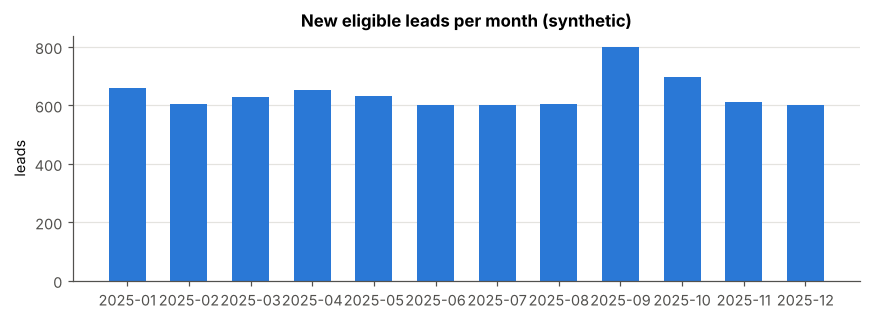

In [3]:
coh = metrics.cohort_table(ctx)
print(f"Snapshot {pop['snapshot']} − 60 × 24 h = {pop['maturity_threshold']}: leads created at or before this instant are mature.")
display(coh[["eligible_leads", "mature_leads", "mature_share", "label", "newest_lead_created_at", "min_age_days",
             "duplicates", "reactivations"]].style.format({"mature_share": pct}))
print(f"Eligible leads: {pop['eligible_leads']:,} · duplicates: {pop['duplicates']:,} · reactivations: {pop['reactivations']:,}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(coh.index.astype(str), coh.eligible_leads, color=BLUE, width=0.6)
ax.set_title("New eligible leads per month (synthetic)"); ax.set_ylabel("leads")
ax.grid(axis="x", visible=False); plt.tight_layout(); plt.show()

## 3. Entry and SLA / Entrada y SLA
**Project analytical definition, not an official historical KPI.** Manual route: first human attempt, measured
in **calendar hours**. Bot route: pre-interview confirmation and human contact, analysed separately.
SLA denominators use manual leads created ≥ 24 h before the snapshot, so every 24-hour window is complete.

The weekday / weekend split shows observed values only. Calendar hours include nights and weekends, when the scenario's
advisors (Mon–Fri 09–19, a synthetic parameter) do not work, so leads arriving outside working hours can be penalised by
this definition. The split does not show that every weekend lead misses the target; whether the SLA should be measured
in calendar or working hours is a definition to validate.
*ES: la división entre semana / fin de semana muestra valores observados. Las horas naturales incluyen noches y fines de semana, en los que los asesores del escenario no trabajan, por lo que esta definición puede penalizar a los leads que entran fuera de horario; no demuestra que todos incumplan.*

In [4]:
sla = metrics.sla_summary(ctx)
display(fmt_rows(sla, counts=["eligible leads"],
                 hours=["manual: median first response (h)", "manual: p90 first response (h)"]))
display(metrics.sla_by_arrival(ctx).style.format({"sla_24h": "{:.1%}", "median_h": "{:.1f}"}))

,value
eligible leads,"7,691"
share manual route,69.9%
share bot route,30.1%
manual: contacted (≥1 human attempt),97.7%
"manual: untouched at snapshot (open, no attempt) / open manual",27.1%
manual: first attempt ≤ 24 h,69.7%
manual: first attempt same calendar day,35.7%
manual: median first response (h),15.9 h
manual: p90 first response (h),59.7 h
contact rate (connected / with attempt),73.5%


,leads,sla_24h,median_h
weekday arrival,4355,77.4%,13.7
weekend arrival,1003,36.3%,28.1


In [5]:
# Bot route: pre-interview confirmation and human contact before the first appointment
bot = metrics.bot_pre_interview(ctx)
print(f"Bot route leads: {bot['bot_route_leads']:,}")
print(f"  with bot confirmation or reminder before first appointment: {pct(bot['confirmation_rate'])}")
print(f"  with human advisor contact before first appointment:        {pct(bot['human_contact_rate'])}")

Bot route leads: 2,317
  with bot confirmation or reminder before first appointment: 99.9%
  with human advisor contact before first appointment:        48.1%


## 4. Main KPI and interview metrics / KPI principal y métricas de entrevista
* **Main KPI (lead level):** mature eligible leads with ≥1 `held` appointment / **all** mature eligible leads, both routes.
* **Per-appointment show rate (appointment level):** `held` / (`held` + `no_show`) over *eligible appointments*:
  eligible lead, not replaced by rescheduling, scheduled ≤ snapshot. Base: month of `interview_scheduled_for`.
* **Per-lead show rate (lead level):** leads with ≥1 `held` / leads with ≥1 eligible appointment `held` or `no_show`.

Partial cohorts are shown with the share of leads included and are NOT compared with mature cohorts.


,cohort_label,mature_share,leads,held,main_kpi,manual_route,bot_route
cohort,,,,,,,
2025-01,mature,100.0%,661,293,44.3%,32.4%,70.5%
2025-02,mature,100.0%,606,279,46.0%,33.5%,75.3%
2025-03,mature,100.0%,628,276,43.9%,32.5%,74.7%
2025-04,mature,100.0%,654,288,44.0%,28.7%,76.3%
2025-05,mature,100.0%,633,287,45.3%,31.1%,74.5%
2025-06,mature,100.0%,600,261,43.5%,30.5%,76.0%
2025-07,mature,100.0%,600,293,48.8%,35.0%,79.3%
2025-08,mature,100.0%,603,271,44.9%,31.4%,81.6%
2025-09,mature,100.0%,798,355,44.5%,29.1%,80.7%


,value
mature eligible leads,"6,487"
MAIN KPI interviews held / opportunities,45.1%
manual route,31.3%
bot route,76.9%
booking rate (≥1 appointment),56.3%


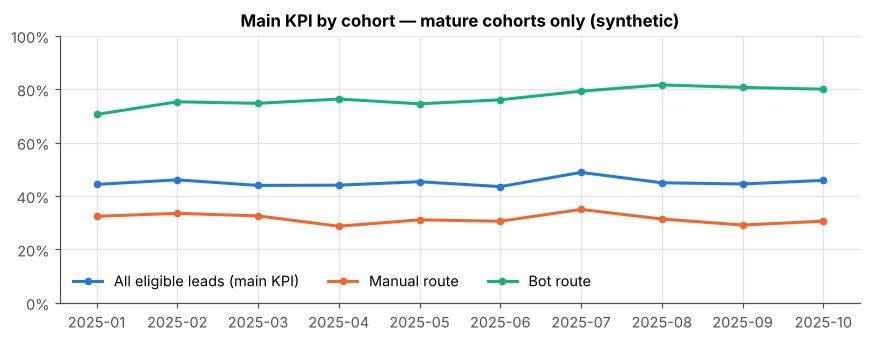

In [6]:
kpi_all = metrics.main_kpi_by_cohort(ctx)
print("Partial cohorts are shown with the share of leads included and are NOT compared with mature cohorts.")
display(kpi_all.style.format({"main_kpi": "{:.1%}", "manual_route": "{:.1%}", "bot_route": "{:.1%}", "mature_share": "{:.1%}"}))
tot = metrics.main_kpi_totals(ctx)
display(fmt_rows(tot, counts=["mature eligible leads"]))

kpi = metrics.main_kpi_by_cohort(ctx, mature_only=True)
fig, ax = plt.subplots(figsize=(8, 3.2))
x = kpi.index.astype(str)
ax.plot(x, kpi.main_kpi, color=BLUE, lw=2, marker="o", ms=4, label="All eligible leads (main KPI)")
ax.plot(x, kpi.manual_route, color=ORANGE, lw=2, marker="o", ms=4, label="Manual route")
ax.plot(x, kpi.bot_route, color=AQUA, lw=2, marker="o", ms=4, label="Bot route")
ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_ylim(0, 1)
ax.set_title("Main KPI by cohort — mature cohorts only (synthetic)")
ax.legend(loc="lower left", ncols=3); plt.tight_layout(); plt.show()

In [7]:
# Appointment-level metrics on eligible appointments
appt = metrics.appointment_metrics(ctx)
ex = appt["excluded"]
print("Appointments excluded from the show rate: rescheduled (replaced) =", ex["rescheduled_replaced"],
      "· pending (future) =", ex["pending_future"], "· cancelled =", ex["cancelled_eligible"], "(cancellation rate only)")
display(appt["rates"].to_frame("value").style.format("{:.1%}"))
print(f"Unit check: {appt['appointments_held_or_no_show']:,} appointments (held+no_show) vs "
      f"{appt['per_lead_denominator']:,} leads in the per-lead denominator")

Appointments excluded from the show rate: rescheduled (replaced) = 444 · pending (future) = 57 · cancelled = 327 (cancellation rate only)


,value
per-appointment show rate (all),69.6%
manual route,75.0%
bot route,65.1%
cancellation rate,6.2%
per-lead show rate (mature cohorts),84.0%


Unit check: 4,932 appointments (held+no_show) vs 3,478 leads in the per-lead denominator


,appointments,show_rate,ci_low,ci_high
personal_wa,,,,
False,1038,68.7%,65.8%,71.4%
True,1546,71.1%,68.8%,73.3%


Interpretation: any difference here is noise or mix, because the scenario programs zero effect.
Estimating a real effect would need a controlled pilot (random assignment of the reminder).


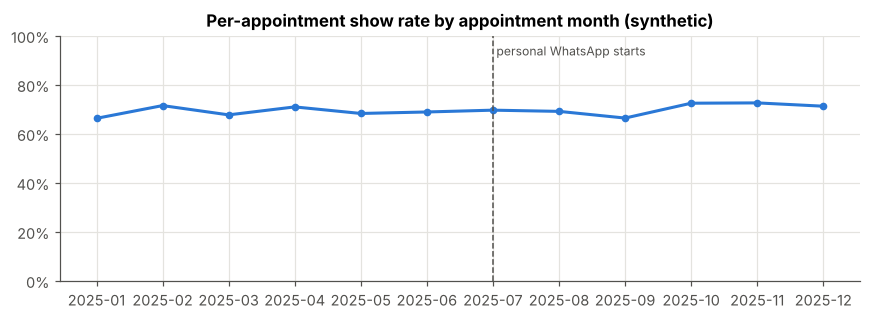

In [8]:
# Personal WhatsApp (from 2025-07-01): ASSOCIATION ONLY. The generator programs ZERO effect on show.
assoc = metrics.personal_whatsapp_association(ctx)
display(assoc.style.format({"show_rate": "{:.1%}", "ci_low": "{:.1%}", "ci_high": "{:.1%}"}))
print("Interpretation: any difference here is noise or mix, because the scenario programs zero effect.\n"
      "Estimating a real effect would need a controlled pilot (random assignment of the reminder).")

m = metrics.show_rate_by_month(ctx)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(m.index.astype(str), m.values, color=BLUE, lw=2, marker="o", ms=4)
ax.axvline("2025-07", color=MUTED, lw=1, ls="--"); ax.text("2025-07", 0.92, " personal WhatsApp starts", color=MUTED, fontsize=8)
ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_ylim(0, 1)
ax.set_title("Per-appointment show rate by appointment month (synthetic)"); plt.tight_layout(); plt.show()

In [9]:
# Robustness: the bot-route main KPI looks higher in Jul–Oct cohorts than in Jan–Jun (same months the personal
# WhatsApp starts). The generator has NO time trend and NO WhatsApp effect. Re-running other seeds shows whether
# the difference is chance. The notebook only orchestrates the experiment; the comparison is metrics.bot_route_half_comparison.
from generate_data import Generator, load_config
rows = {42: metrics.bot_route_half_comparison(ctx.raw_leads)}
cfg_s = load_config(ROOT / "config" / "simulation_params.yaml")
for seed in (1, 2, 3):
    cfg_s["seed"] = seed
    rows[seed] = metrics.bot_route_half_comparison(Generator(cfg_s).run()[0])
display(pd.DataFrame(rows).T.rename_axis("seed").style.format({"Jan–Jun": "{:.1%}", "Jul–Oct": "{:.1%}", "z": "{:+.1f}"}))
print("Seed 42 shows a sizeable gap; other seeds do not. With zero programmed effect, the gap is chance —\n"
      "a reminder that a before/after comparison cannot attribute causality.")

,Jan–Jun,Jul–Oct,z
seed,,,
42,74.5%,80.3%,+3.0
1,77.9%,76.6%,-0.7
2,76.7%,77.0%,+0.1
3,78.3%,77.6%,-0.4


Seed 42 shows a sizeable gap; other seeds do not. With zero programmed effect, the gap is chance —
a reminder that a before/after comparison cannot attribute causality.


## 5. Funnel (mature cohorts) / Funnel (cohortes maduras)
Lead-level counts of leads that reached each milestone. Directional metrics: forms / held, enrollments / held.

,leads,% of eligible,% of previous
eligible leads,6487,100.0%,—
interview booked,3651,56.3%,56.3%
interview held,2923,45.1%,80.1%
form completed,1255,19.3%,42.9%
enrollment link sent,1042,16.1%,83.0%
enrolled,684,10.5%,65.6%


,value
forms completed / interviews held,42.9%
enrollments / interviews held,23.4%
links / forms,83.0%
enrollments / eligible leads,10.5%


Sales cycle (created → enrolled), days: median 17.0 · mean 18.2 · n=684


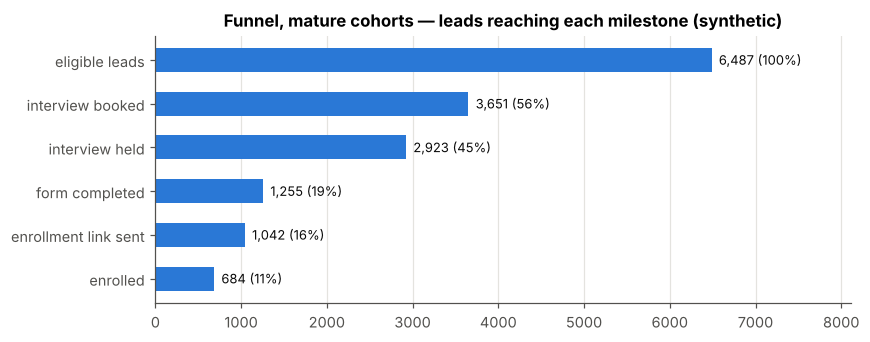

In [10]:
fun = metrics.funnel(ctx)
display(fun.style.format({"% of eligible": "{:.1%}", "% of previous": "{:.1%}"}, na_rep="—"))
dirm = metrics.directional_rates(ctx)
display(dirm.to_frame("value").style.format("{:.1%}"))
cyc = metrics.sales_cycle(ctx)
print(f"Sales cycle (created → enrolled), days: median {cyc['median_days']:.1f} · mean {cyc['mean_days']:.1f} · n={cyc['n']}")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(fun.index[::-1], fun.leads[::-1], color=BLUE, height=0.55)
for y, (v, p) in enumerate(zip(fun.leads[::-1], fun["% of eligible"][::-1])):
    ax.text(v, y, f"  {v:,} ({p:.0%})", va="center", color=INK, fontsize=8.5)
ax.set_xlim(0, fun.leads.max() * 1.25); ax.grid(axis="y", visible=False)   # axis limit only (presentation)
ax.set_title("Funnel, mature cohorts — leads reaching each milestone (synthetic)"); plt.tight_layout(); plt.show()

## 6. Sources, profiles and programmes / Fuentes, perfiles y programas
Quality = downstream conversion and net price per lead, not volume. **These differences reproduce the channel and
profile modifiers in the scenario configuration**; they demonstrate the method, not real channel performance.

In [11]:
fmt = {c: "{:.1%}" for c in ["held / leads", "enrolled / leads", "enrolled / held", "ILOC share"]} | {"net € per lead": "{:,.0f}"}
for by in ("channel_group", "candidate_profile", "program_alias"):
    display(metrics.segment_table(ctx, by).style.format(fmt).set_caption(f"By {by} — mature cohorts (synthetic)"))

,leads,held / leads,enrolled / leads,enrolled / held,ILOC share,net € per lead
channel_group,,,,,,
paid_social,2912,36.5%,5.8%,15.8%,33.5%,146
webinar,1646,56.4%,16.6%,29.5%,21.0%,419
web_direct,760,48.7%,10.3%,21.1%,24.6%,261
organic,532,47.9%,10.7%,22.4%,27.6%,270
referral,330,54.5%,20.9%,38.3%,21.8%,531
event,172,40.7%,12.2%,30.0%,32.6%,302
partner,135,40.7%,12.6%,30.9%,25.2%,318


,leads,held / leads,enrolled / leads,enrolled / held,ILOC share,net € per lead
candidate_profile,,,,,,
healthcare,3545,44.2%,11.0%,24.8%,28.9%,278
non_healthcare,2942,46.1%,10.0%,21.8%,26.9%,252


,leads,held / leads,enrolled / leads,enrolled / held,ILOC share,net € per lead
program_alias,,,,,,
PRG_A,2131,44.9%,11.5%,25.7%,28.4%,294
PRG_C,1653,45.9%,9.6%,20.8%,27.6%,239
PRG_B,1370,43.8%,10.7%,24.3%,29.2%,268
PRG_D,1333,45.6%,10.1%,22.0%,26.6%,254


## 7. Advisors — exploratory only / Asesores — solo exploratorio
All five advisors share **the same base parameters**; the uneven *assignment weight* is a scenario parameter, not
a real distribution. Differences in workload or conversion come from chance, the assignment weight and
reassignments; **they are not attributed to individual performance.**
Workload = eligible leads by `first_owner_id` and month (duplicates excluded; reactivations shown separately).

Realised workload (eligible leads by first owner and month):


cohort,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
first_owner_id,,,,,,,,,,,,
ADV_01,154,146,154,144,147,116,136,136,179,171,138,133
ADV_02,158,121,133,136,129,135,122,116,161,141,123,131
ADV_03,131,118,123,118,130,130,117,143,168,140,121,126
ADV_04,113,120,112,141,125,106,115,121,148,131,128,122
ADV_05,105,101,106,115,102,113,110,87,142,113,102,88


Advisor-months by band (realised): {'<100': 2, '100-120 usual': 19, '121-150 high': 32, '>150 alert': 7}
Advisor-months >150 — expected before randomness: 4 · realised: 7
Reactivations by first owner (separate from workload): {'ADV_01': 16, 'ADV_02': 23, 'ADV_03': 16, 'ADV_04': 20, 'ADV_05': 25}


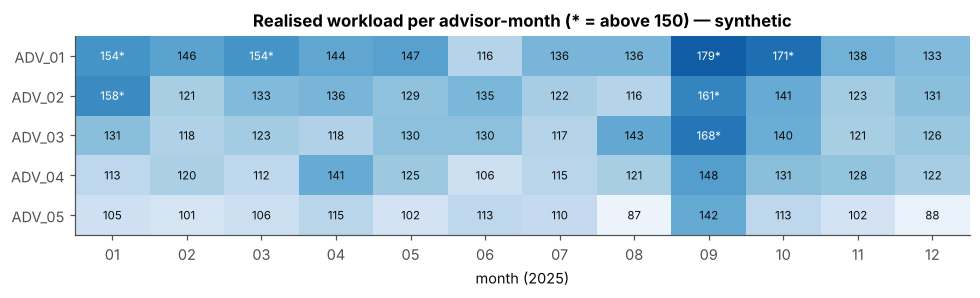

In [12]:
wl = metrics.workload(ctx)
work = wl["realised"]
print("Realised workload (eligible leads by first owner and month):")
display(work)
print("Advisor-months by band (realised):", wl["bands"])
print("Advisor-months >150 — expected before randomness:", wl["over_150_expected"], "· realised:", wl["over_150_realised"])
print("Reactivations by first owner (separate from workload):", wl["reactivations_by_first_owner"])

fig, ax = plt.subplots(figsize=(9, 2.8))
im = ax.imshow(work.values, cmap="Blues", aspect="auto", vmin=80, vmax=200)
ax.set_xticks(range(work.shape[1]), [str(c)[-2:] for c in work.columns]); ax.set_yticks(range(work.shape[0]), work.index)
for i in range(work.shape[0]):
    for j in range(work.shape[1]):
        v = work.values[i, j]
        ax.text(j, i, f"{v}{'*' if v > 150 else ''}", ha="center", va="center", fontsize=7.5, color="white" if v > 150 else INK)
ax.grid(False); ax.set_xlabel("month (2025)")
ax.set_title("Realised workload per advisor-month (* = above 150) — synthetic"); plt.tight_layout(); plt.show()

In [13]:
f = {c: "{:.1%}" for c in ["held / leads", "95% CI low", "95% CI high", "enrolled / leads", "manual SLA ≤24h"]}
display(metrics.advisor_table(ctx, "first_owner_id").style.format(f).set_caption("By first owner — exploratory (synthetic)"))
display(metrics.advisor_table(ctx, "current_owner_id").style.format(f).set_caption("By current owner — exploratory (synthetic)"))
print("Advisor activities by performer (actor_id):", metrics.advisor_activity_counts(ctx))

,n leads,held / leads,95% CI low,95% CI high,enrolled / leads,manual SLA ≤24h
advisor,,,,,,
ADV_01,1485,45.0%,42.5%,47.5%,10.2%,70.2%
ADV_02,1355,45.6%,43.0%,48.3%,10.7%,68.7%
ADV_03,1319,45.6%,43.0%,48.3%,11.3%,71.6%
ADV_04,1233,44.1%,41.4%,46.9%,9.7%,70.1%
ADV_05,1095,44.8%,41.9%,47.8%,11.0%,68.7%


,n leads,held / leads,95% CI low,95% CI high,enrolled / leads,manual SLA ≤24h
advisor,,,,,,
ADV_01,1500,45.2%,42.7%,47.7%,10.5%,69.1%
ADV_02,1349,45.8%,43.2%,48.5%,10.9%,69.1%
ADV_03,1331,45.8%,43.1%,48.4%,11.0%,70.6%
ADV_04,1226,43.5%,40.7%,46.3%,10.1%,70.7%
ADV_05,1081,44.9%,41.9%,47.8%,10.2%,69.9%


Advisor activities by performer (actor_id): {'ADV_01': 13158, 'ADV_02': 12025, 'ADV_03': 12065, 'ADV_04': 11191, 'ADV_05': 10079}


## 8. Losses and nurture / Pérdidas y nurture

In [14]:
lr = metrics.lost_reasons(ctx)
display(lr["by_exit_point"])
display(lr["distribution"].to_frame("share of closed-lost with reason").style.format("{:.1%}"))

nu = metrics.nurture_summary(ctx)
print(f"Entered nurture: {nu['entered_nurture']:,} deals · with a complete 150-day window by the snapshot: {nu['complete_window']:,}")
print(f"  reactivated within the window (complete windows only): {pct(nu['reactivation_rate_complete_window'])}")
print(f"  reactivated leads that enrolled (any window): {nu['reactivated_enrolled']} of {nu['reactivated_leads']}")
print(f"  nurture emails not sent or failed: {pct(nu['email_failure_rate'])} of {nu['nurture_emails']:,}")

reason,(missing — DQ anomaly),financial,future_intake,iloc,official_qualification,All
exit_point,,,,,,
after booking,20,134,142,398,121,815
after form,10,83,97,0,0,190
after interview held,81,639,589,0,413,1722
after link,13,215,157,0,0,385
before booking,63,482,445,1686,450,3126
All,187,1553,1430,2084,984,6238


,share of closed-lost with reason
lost_reason,
iloc,34.4%
financial,25.7%
future_intake,23.6%
official_qualification,16.3%


Entered nurture: 1,238 deals · with a complete 150-day window by the snapshot: 697
  reactivated within the window (complete windows only): 12.2%
  reactivated leads that enrolled (any window): 8 of 100
  nurture emails not sent or failed: 15.1% of 3,001


## 9. CRM governance at the snapshot / Gobernanza CRM en la fecha de corte
Simple indicators (no weighted score in v1). Deliberate anomalies are part of the scenario.

**Manual advisor follow-up within 48 h** (project analytical definition of the operational 24–48 h alert rule, which did not
specify calendar or working hours):
* *Counts:* advisor activities with `actor_type = advisor`, `direction = outbound`, `activity_type` in {call, whatsapp} and
  `is_automated = false`. Automated or templated emails, bot messages, tasks and notes do not count.
* *Window:* calendar hours, from the first held interview (`entered_interview_held_at`, exclusive) to 48 h later (inclusive).
  Weekends are **not** excluded.
* *Denominator:* eligible leads whose first held interview is at least 48 h before the snapshot (complete window).

*ES: cuentan llamadas y WhatsApps salientes manuales del asesor; ventana de 48 horas naturales desde la primera entrevista realizada, sin excluir fines de semana; denominador: leads elegibles con la primera entrevista realizada al menos 48 h antes del corte.*

In [15]:
gv = metrics.governance(ctx)
display(fmt_rows(gv["indicators"], counts=["open leads at snapshot",
                                           "follow-up 48 h — denominator (eligible, window complete)",
                                           "follow-up 48 h — numerator (≥1 manual call/WhatsApp in window)"]))
fu = gv["followup"]
print(f"Follow-up 48 h: {fu['numerator']:,} / {fu['denominator']:,} = {pct(fu['rate'])} "
      "(row-level recount: tests/test_integrity.py::test_followup_indicator_on_dataset_matches_row_level_recount).")
print(f"Leads in the denominator with manual advisor activity BEFORE the interview: "
      f"{gv['followup_leads_with_pre_interview_activity']:,} — those earlier activities are not counted.")
print("This is a result of this synthetic run: the generator plans 80 % of follow-ups within 48 calendar hours and then\n"
      "moves advisor activity to working hours (assumptions §3.9). It describes the scenario, not a team's performance.")
print("Open leads by stage:", gv["open_by_stage"])
print("Open leads that are deliberate anomalies (stalled or untouched):", gv["open_deliberate_anomalies"])

,value
open leads at snapshot,671
open without next task,7.2%
open with overdue task,46.8%
"follow-up 48 h — denominator (eligible, window complete)","3,403"
follow-up 48 h — numerator (≥1 manual call/WhatsApp in window),"2,118"
held with manual advisor follow-up within 48 calendar hours,62.2%
closed-lost without reason,3.0%
held with ≥1 empty post-interview field,10.0%
duplicates / all rows,1.9%


Follow-up 48 h: 2,118 / 3,403 = 62.2% (row-level recount: tests/test_integrity.py::test_followup_indicator_on_dataset_matches_row_level_recount).
Leads in the denominator with manual advisor activity BEFORE the interview: 2,617 — those earlier activities are not counted.
This is a result of this synthetic run: the generator plans 80 % of follow-ups within 48 calendar hours and then
moves advisor activity to working hours (assumptions §3.9). It describes the scenario, not a team's performance.
Open leads by stage: {'interview_held': 253, 'opportunity': 246, 'interview_booked': 73, 'form_completed': 72, 'enrollment_link_sent': 27}
Open leads that are deliberate anomalies (stalled or untouched): 399


## 10. Finance (synthetic pricing rule) / Finanzas (regla de precio sintética)
Single payment: (3,200 − campaign discount) × 0.85. Instalments: 3,200 − campaign discount. The campaign discount
is drawn at random (arbitrary scenario), so no campaign seasonality can be analysed. No payments or collections.

In [16]:
fin = metrics.finance(ctx)
display(fin["summary"].to_frame("value").style.format("{:,.0f}"))
print("Observed ticket range in the operational context: €2,000–2,500. The synthetic rule is not calibrated to it:"
      " instalment net prices (€2,600–2,850) sit above that range by construction.")
display(fin["by_payment_type"].style.format({"avg_net": "{:,.0f}", "total_net": "{:,.0f}", "mix": "{:.1%}"}))
display(fin["price_grid"].style.format("{:,.2f}").set_caption("Net price by campaign discount and payment type (rule check)"))

,value
enrollments,782
gross list value €,"2,502,400"
campaign discount €,"382,050"
one-time discount €,"148,275"
net price €,"1,972,075"
average net price €,"2,522"


Observed ticket range in the operational context: €2,000–2,500. The synthetic rule is not calibrated to it: instalment net prices (€2,600–2,850) sit above that range by construction.


,enrollments,avg_net,total_net,mix
payment_type,,,,
installments,417,"2,714","1,131,850",53.3%
single,365,"2,302","840,225",46.7%


payment_type,installments,single
campaign_discount,,
350.000000,"2,850.00","2,422.50"
500.000000,"2,700.00","2,295.00"
600.000000,"2,600.00","2,210.00"


## 11. Baseline metrics and reconciliation with F0 / Métricas de la línea base y conciliación con F0
The 47 baseline metrics are computed by `metrics.baseline_metrics` and compared with the frozen F0 reference
`baseline/metrics_v1.json` by `metrics.reconcile` (values at the reference rounding of 6 decimals, no extra tolerance;
numerators, denominators and descriptive fields exactly equal). The notebook writes no files: the F1 metrics document
is written by `scripts/export_metrics.py` to `reports/f1/metrics_f1.json`, and `baseline/` stays frozen.
*ES: las 47 métricas las calcula `metrics.baseline_metrics` y `metrics.reconcile` las compara con la referencia congelada de F0;
el notebook no escribe archivos y `baseline/` queda congelada.*

In [17]:
import json
reference = json.loads((ROOT / "baseline" / "metrics_v1.json").read_text(encoding="utf-8"))
doc = metrics.baseline_document(ctx, "v1.1.0-f1", ROOT)
rs = metrics.reconciliation_summary(doc, reference)
rec = rs["table"]
print(f"Metrics: {rs['metrics']} · matching F0: {rs['matching']} · missing from F1: {rs['missing_from_document'] or 'none'}")
print("Cohort maturity, anomaly reconciliation, logic checks and input hashes identical to F0:", rs["other_sections_identical"])
display(rec[["value_reference", "value", "abs_diff", "numerator_reference", "numerator", "denominator_reference",
             "denominator", "descriptive_equal", "match"]])

Metrics: 47 · matching F0: 47 · missing from F1: none
Cohort maturity, anomaly reconciliation, logic checks and input hashes identical to F0: True


,value_reference,value,abs_diff,numerator_reference,numerator,denominator_reference,denominator,descriptive_equal,match
id,,,,,,,,,
eligible_leads,7691,7691,0,7691,7691,None,None,True,True
mature_eligible_leads,6487,6487,0,6487,6487,None,None,True,True
duplicate_rows,154,154,0,154,154,None,None,True,True
reactivation_rows,100,100,0,100,100,None,None,True,True
share_manual_route,0.698739,0.698739,0.0,5374,5374,7691,7691,True,True
main_kpi_interviews_held_over_opportunities,0.450593,0.450593,0.0,2923,2923,6487,6487,True,True
held_rate_manual_route,0.313258,0.313258,0.0,1420,1420,4533,4533,True,True
held_rate_bot_route,0.769191,0.769191,0.0,1503,1503,1954,1954,True,True
booking_rate,0.562818,0.562818,0.0,3651,3651,6487,6487,True,True


## 12. Key figures and conclusions / Cifras clave y conclusiones

In [18]:
k = metrics.key_figures(ctx)
display(pd.Series({
    "Eligible leads (12 months)": f"{k['eligible_leads']:,}",
    "Mature eligible leads": f"{k['mature_eligible_leads']:,}",
    "MAIN KPI — interviews held / opportunities": pct(k["main_kpi"]),
    "  manual route / bot route": f"{pct(k['main_kpi_manual'])} / {pct(k['main_kpi_bot'])}",
    "Per-appointment show rate": pct(k["show_rate_per_appointment"]),
    "Forms / interviews held": pct(k["forms_over_held"]),
    "Enrollments / interviews held": pct(k["enrollments_over_held"]),
    "Manual first attempt ≤ 24 h": pct(k["sla_24h_manual"]),
    "Advisor-months > 150 (realised)": k["advisor_months_over_150_realised"],
    "Average net price (€)": f"{k['average_net_price']:,.0f}",
}).to_frame("synthetic value"))

,synthetic value
Eligible leads (12 months),"7,691"
Mature eligible leads,"6,487"
MAIN KPI — interviews held / opportunities,45.1%
manual route / bot route,31.3% / 76.9%
Per-appointment show rate,69.6%
Forms / interviews held,42.9%
Enrollments / interviews held,23.4%
Manual first attempt ≤ 24 h,69.7%
Advisor-months > 150 (realised),7
Average net price (€),"2,522"


### EN — What this synthetic run shows (all figures synthetic, seed 42)

1. **Main KPI.** 45.1 % of mature eligible leads had at least one held interview. On the manual route it is 31.3 %; on the bot route 76.9 %. The gap comes from the scenario design (bot-route leads arrive with an appointment). An Opportunity-only denominator would leave the bot route out entirely.
2. **Units matter.** The per-appointment show rate is 69.6 %, while the per-lead show rate is 84.0 %. They answer different questions, and mixing them would misstate attendance.
3. **Funnel.** Forms / interviews held = 42.9 % and enrollments / interviews held = 23.4 %, with a median sales cycle of 17 days. ILOC accounts for 34.4 % of the losses that have a reason.
4. **SLA, as defined here.** 69.7 % of manual leads got a first human attempt within 24 calendar hours (median 15.9 h). The observed value is 77.4 % for weekday arrivals and 36.3 % for weekend arrivals. Calendar hours include periods when the scenario's advisors do not work, so this definition can penalise leads that arrive outside working hours. The split describes this scenario; whether to measure in calendar or working hours is a definition to validate.
5. **Post-interview follow-up, as defined here.** In this synthetic run, 2,118 of 3,403 eligible leads whose 48-hour window closed before the snapshot (62.2 %) had a manual advisor call or WhatsApp after the interview and within 48 calendar hours of it. This is an output of the scenario parameters and the generator's working-hours assumption; it is not a measure of real performance or a finding about any team.
6. **Sources.** Webinar and referral leads convert more and paid social less, both to held interview and to enrollment. This reproduces the channel modifiers in the configuration and illustrates the method, not real channel performance.
7. **Advisors.** Advisor-months above 150 leads: 7 realised (4 expected before randomness), driven by the September volume and the uneven assignment weight. Conversion confidence intervals overlap for all five advisors, which is consistent with identical parameters. Nothing is attributable to individual performance.
8. **No causality.** Show rate with and without the personal WhatsApp is 71.1 % vs 68.7 %, with overlapping intervals. On the bot route, Jul–Oct cohorts look better than Jan–Jun (z ≈ 3) although no effect is programmed, and other seeds show no gap. Estimating a real effect would need a controlled pilot.
9. **Governance and data quality.** 671 leads are open at the snapshot; 399 of them are deliberate anomalies (stalled or untouched). 7.2 % have no next task and 46.8 % have an overdue task. For six anomaly types, detected equals injected. For the other two, the cases not yet observable at the snapshot are counted separately: 1 of 116 untouched leads (created < 10 days before the snapshot) and 20 of 286 stalled leads (idle < 30 days).
10. **Finance.** The average net price is €2,522 (single €2,302, instalments €2,714). Instalments make up 53.3 % of enrollments. The synthetic rule is not calibrated to the observed €2,000–2,500 ticket.

### ES — Qué muestra esta ejecución sintética (todas las cifras son sintéticas, semilla 42)

1. **KPI principal.** El 45,1 % de los leads elegibles maduros tuvo al menos una entrevista realizada. En la ruta manual es el 31,3 % y en la ruta bot el 76,9 %. La diferencia procede del diseño del escenario (los leads de la ruta bot llegan con cita). Un denominador limitado a la etapa Opportunity dejaría fuera la ruta bot.
2. **La unidad importa.** El show rate por cita es del 69,6 % y el show rate por lead del 84,0 %. Responden a preguntas distintas, y mezclarlos distorsionaría la asistencia.
3. **Funnel.** Formularios / entrevistas realizadas = 42,9 % y matrículas / entrevistas realizadas = 23,4 %, con un ciclo de venta mediano de 17 días. El ILOC supone el 34,4 % de las pérdidas con motivo.
4. **SLA, según la definición del proyecto.** El 69,7 % de los leads manuales recibió un primer intento humano en 24 horas naturales (mediana de 15,9 h). El valor observado es del 77,4 % para los leads que entran entre semana y del 36,3 % para los que entran en fin de semana. Las horas naturales incluyen periodos en los que los asesores del escenario no trabajan, así que esta definición puede penalizar a los leads que entran fuera de horario. La división describe este escenario; medir en horas naturales o laborables es una definición a validar.
5. **Seguimiento postentrevista, según la definición del proyecto.** En esta ejecución sintética, 2.118 de los 3.403 leads elegibles cuya ventana de 48 horas había terminado antes del corte (62,2 %) tuvieron una llamada o un WhatsApp manual del asesor después de la entrevista y dentro de las 48 horas naturales siguientes. Es un resultado de los parámetros del escenario y del supuesto de horario laboral del generador; no mide un desempeño real ni es un hallazgo sobre ningún equipo.
6. **Fuentes.** Los leads de webinar y referidos convierten más y los de paid social menos, tanto a entrevista realizada como a matrícula. Esto reproduce los modificadores por canal de la configuración e ilustra el método, no el rendimiento real de los canales.
7. **Asesores.** Meses-asesor por encima de 150 leads: 7 realizados (4 esperados antes del azar), por el volumen de septiembre y el peso de asignación desigual. Los intervalos de confianza de conversión se solapan para los cinco asesores, lo que es coherente con parámetros idénticos. No hay nada atribuible al desempeño individual.
8. **Sin causalidad.** El show rate con y sin WhatsApp personalizado es 71,1 % frente a 68,7 %, con intervalos solapados. En la ruta bot, las cohortes de julio a octubre parecen mejores que las de enero a junio (z ≈ 3) aunque no se programa ningún efecto, y con otras semillas la diferencia desaparece. Para estimar un efecto real haría falta un piloto controlado.
9. **Gobernanza y calidad de datos.** Hay 671 leads abiertos en la fecha de corte; 399 de ellos son anomalías deliberadas (estancados o sin tocar). El 7,2 % no tiene próxima tarea y el 46,8 % tiene una tarea vencida. En seis tipos de anomalía, lo detectado coincide con lo inyectado. En los otros dos, los casos aún no observables en la fecha de corte se cuentan aparte: 1 de 116 leads sin tocar (creado menos de 10 días antes del corte) y 20 de 286 leads estancados (inactivos menos de 30 días).
10. **Finanzas.** El precio neto medio es de 2.522 € (pago único 2.302 €, fraccionado 2.714 €). El pago fraccionado supone el 53,3 % de las matrículas. La regla sintética no está calibrada con el ticket observado de 2.000–2.500 €.